# Historical evidence published on the website
Audit of the catalog of official references and their satellite witnesses.
A space-time association does not verify attribution or physical ignition.
This notebook keeps every result, including the non-matching ones.

In [1]:
from pathlib import Path
import gzip,hashlib,json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'web/validation-data/summary.json').exists())
folder=repo/'web/validation-data'
summary=json.loads((folder/'summary.json').read_text(encoding='utf-8'))
cases=[]
for entry in summary['years']:
    raw=(folder/entry['file']).read_bytes()
    assert hashlib.sha256(raw).hexdigest()==entry['sha256']
    assert gzip.decompress((folder/entry['compressed_file']).read_bytes())==raw
    cases.extend(json.loads(raw)['data'])
data=pd.DataFrame(cases)
assert len(data)==15140 and data.id.is_unique
print('Referencias conservadas:',len(data))
print('Ubicaciones originales agrupadas:',data.registry_locations.sum())
display(data.match_status.value_counts().rename_axis('resultado').rename('referencias').to_frame())

Referencias conservadas: 15140
Ubicaciones originales agrupadas: 22473


,referencias
resultado,
none,7974
viirs,4192
both,2638
modis,336


## One rule and the full denominator
LAEA distance up to 5 km and ±3 full days of the local calendar. The
controls shift the date by ±28 days at the same place. They are not verified
negatives or an estimate of the false-positive rate.

,instrument,date_shift_days,incident_references,with_satellite_record,association_fraction
0,MODIS,0,15140,2974,0.196433
9,MODIS,-28,15140,1026,0.067768
18,MODIS,28,15140,917,0.060568
27,VIIRS,0,15140,6830,0.451123
36,VIIRS,-28,15140,2919,0.192801
45,VIIRS,28,15140,2640,0.174373


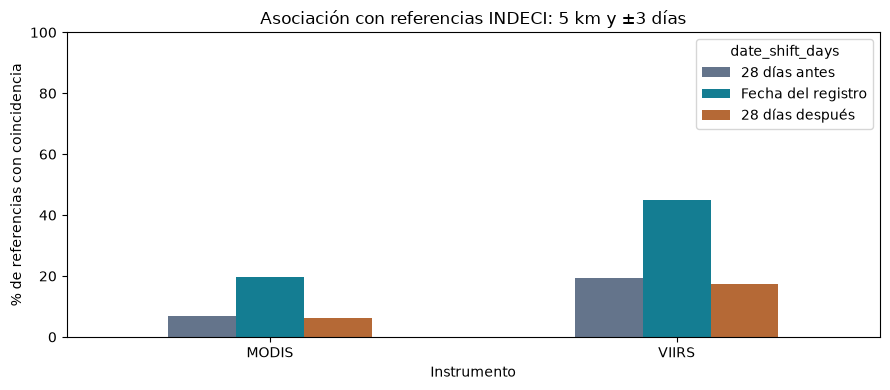

In [2]:
scores=pd.DataFrame(summary['associations'])
primary=scores.loc[scores.origin.eq('INDECI')&scores.radius_km.eq(5)]
display(primary[['instrument','date_shift_days','incident_references','with_satellite_record','association_fraction']])
plot=primary.pivot(index='instrument',columns='date_shift_days',values='association_fraction')*100
plot=plot.reindex(columns=[-28,0,28]).rename(columns={-28:'28 días antes',0:'Fecha del registro',28:'28 días después'})
ax=plot.plot.bar(figsize=(9,4),rot=0,color=['#64748b','#147d92','#b56936'])
ax.set_ylabel('% de referencias con coincidencia');ax.set_xlabel('Instrumento')
ax.set_title('Asociación con referencias INDECI: 5 km y ±3 días')
ax.set_ylim(0,100);ax.figure.tight_layout();plt.show()

## Traceable examples, without hiding the cases with no match
Each year is a full partition, not a selection of successes. The witnesses
keep official IDs, dates, coordinates, distance and the row of the FIRMS file.
The absence of a match does not prove absence of fire or a sensor omission.

In [3]:
for status in ['both','modis','viirs','none']:
    print('Resultado:',status)
    display(data.loc[data.match_status.eq(status),['id','date_start','departments','registry_object_ids','matches']].head(2))
assert sum(data.matches.map(lambda rows:any(r['instrument']=='MODIS' for r in rows)))==2974
assert sum(data.matches.map(lambda rows:any(r['instrument']=='VIIRS' for r in rows)))==6830

Resultado: both


,id,date_start,departments,registry_object_ids,matches
2,INDECI|code|00061285,2013-10-23,[CUSCO],[1128],"[{'instrument': 'MODIS', 'platform': 'Aqua', '..."
5,INDECI|code|00061186,2013-10-17,[CUSCO],[1108],"[{'instrument': 'MODIS', 'platform': 'Aqua', '..."


Resultado: modis


,id,date_start,departments,registry_object_ids,matches
6,INDECI|code|00061231,2013-10-11,[PUNO],[1037],"[{'instrument': 'MODIS', 'platform': 'Aqua', '..."
28,INDECI|code|00061259,2013-09-17,[CUSCO],[1154],"[{'instrument': 'MODIS', 'platform': 'Aqua', '..."


Resultado: viirs


,id,date_start,departments,registry_object_ids,matches
0,INDECI|code|00061930,2013-11-18,[CUSCO],[4167],"[{'instrument': 'VIIRS', 'platform': 'Suomi-NP..."
7,INDECI|code|00061693,2013-10-09,[PUNO],[1400],"[{'instrument': 'VIIRS', 'platform': 'Suomi-NP..."


Resultado: none


,id,date_start,departments,registry_object_ids,matches
1,INDECI|code|00061935,2013-11-16,[CUSCO],[4133],[]
3,INDECI|code|00061700,2013-10-22,[PUNO],[1257],[]


## Sources and recent check
The current sample of 13 rows checks attributes and geometry against the official
service. It does not verify every row live or prove that
the source is independent from satellite products. The PDFs of the Curimaná case
keep the hashes of the earlier study.

In [4]:
display(summary['source_snapshot'])
display(summary['live_source_verification'])
for document in summary['case_study']['document_hashes']:
    assert hashlib.sha256((folder/'documents'/document['file']).read_bytes()).hexdigest()==document['sha256']
display(summary['case_study'])

{'source': 'https://geoservidorperu.minam.gob.pe/arcgis/rest/services/ServicioCFOI/MapServer/1',
 'layer': 'Registro histórico de incendios 2000-2025',
 'downloaded_at_utc': '2026-11-15T03:44:33.397244+00:00',
 'rows': 54493,
 'object_id_manifest_sha256': 'bc9958e1d6003e6f9fffb93874c3cd740234838dfd0673cb61d8d3f3368958ec',
 'csv_sha256': '77e4df26fe8e6f6e3c37cac1d2893f9c93fe4a2a8b32ccd4567a0b38bea6a3ae',
 'object_ids_complete': True,
 'date_is_registration_or_emergency_not_verified_ignition': True,
 'independence_from_satellite_products_not_established': True,
 'relation_to_user_portal': 'official MINAM layer with matching registry title; portal resource inaccessible (403), exact resource identity not yet proven'}

{'checked_at': '2026-11-15T23:01:04.314289+00:00',
 'sample_rows': 13,
 'object_ids': [1120,
  1475,
  1714,
  6915,
  2389,
  84,
  8337,
  14672,
  14726,
  18346,
  30126,
  37238,
  48397],
 'fields_and_geometry_match': True,
 'all_rows_checked_live': False}

{'progress_harmonization_percent': 65,
 'harmonized': False,
 'event_spec': {'event_id': 'coen_2019_curimana_dos_de_mayo',
  'anchor_longitude': -75.15789724255865,
  'anchor_latitude': -8.453540639633092,
  'anchor_kind': 'Mean of ANA riverbank vertices adjacent to locality, NOT fire coordinates',
  'anchor_fire_position_error_km': None,
  'start_local': '2019-08-31 17:30:00-05:00',
  'end_local': '2019-09-02 02:00:00-05:00',
  'start_utc': '2019-08-31 22:30:00+00:00',
  'end_utc': '2019-09-02 07:00:00+00:00',
  'timezone_assumption': 'Reported clock times interpreted as America/Lima',
  'primary_radius_m': 2000,
  'radii_m': [1000, 2000, 5000],
  'temporal_margins_hours': [0, 6, 24],
  'context_days': 7,
  'platforms': ['Aqua', 'Suomi-NPP'],
  'processing': 'SP',
  'type': 0,
  'status': 'exploratory neighborhood compatibility, no incident attribution'},
 'event_spec_sha256': '1da5e0f82b46b9d78c2f04e04e9b1e209c94e9a549192199a0190392bbeff891',
 'data_sources': [{'file': 'fire_archive_

## What this evidence allows us to claim
It allows showing concrete historical associations, with denominators and sources.
It does not verify that each detection corresponds to the reported fire, it does not validate the
global harmonization scale through correlation and it does not validate the risk of future physical
ignition. The model evaluation uses indirect labels and is shown
separately; it is not presented as a hit rate against real fires.

In [5]:
display(pd.DataFrame(summary['model_evaluation']))
display(summary['interpretation'])
assert not any(summary['interpretation'].values())
print('Sección: /visor/#validacion')
print('Datos: /visor/validation-data/summary.json')

,period,model,brier,rows,positive_fraction
0,2024,climatology,0.082997,15600,0.823141
1,2024,lgbm_without_harmonization,0.083020,15600,0.823141
2,2025,climatology,0.074349,13650,0.835897
3,2025,lgbm_without_harmonization,0.067818,13650,0.835897
4,confirmation_2026,climatology,0.092859,7050,0.792624
5,confirmation_2026,lgbm_without_harmonization,0.089194,7050,0.792624


{'association_is_verified_attribution': False,
 'unmatched_is_proven_omission': False,
 'ground_incident_independence_established': False,
 'physical_ignition_forecast_validated': False,
 'registry_is_count_of_independent_physical_fires': False}

Sección: /visor/#validacion
Datos: /visor/validation-data/summary.json
